In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interactive
import seaborn as sns
sns.set_theme(style="ticks", font_scale=1.5)
%matplotlib widget

In [2]:
import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

interactive(children=(FloatSlider(value=15.0, description='Tmiddle', max=17.0, min=-4.0, step=0.5), FloatSlide…

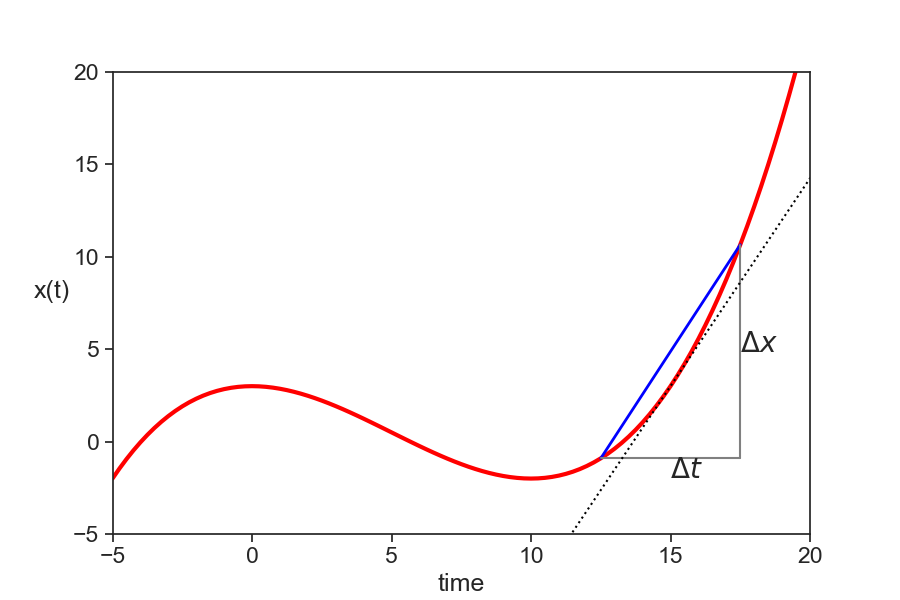

In [3]:
fig, ax = plt.subplots(figsize=(9,6))
t = np.linspace(-5, 20, 101)
foo = lambda t: (t**3 - 15*t**2 + 300) / 100
x = foo(t)
Tmiddle = 15
deltaT = 5

ax.set(xlim=[-5,20],
       ylim=[-5,20],
       ylabel="y",
       xticks=np.arange(-5,21,5),
       xlabel="time",
      )
ax.set_ylabel("x(t)", rotation="horizontal",labelpad=15)


def plot_all_lines(T, dt):
    ax.plot(t, x, color="red", lw=3)
    t0 = T - dt/2
    t1 = T + dt/2
    x0 = foo(t0)
    x1 = foo(t1)
    ax.plot([t0,t1], [x0,x1], color="blue", lw=2)
    
    ax.plot([t0,t1], [x0,x0], color="gray")
    ax.plot([t1,t1], [x0,x1], color="gray")
    ax.text(T, x0, r"$\Delta t$", fontsize=20, va="top")
    ax.text(t1, (x1+x0)/2, r"$\Delta x$", fontsize=20)
    
    slope = (3*T**2 - 30*T) / 100
    intercept = foo(T) - slope*T
    Tmin = -100
    Tmax = 100
    line = lambda t: slope*t + intercept
    ax.plot([Tmin, Tmax], [line(Tmin), line(Tmax)],
            color="black", ls=":")
    
plot_all_lines(Tmiddle, deltaT)

@widgets.interact(Tmiddle=(-4, 17, 0.5), deltaT=(0, 8, 0.2))
def update(Tmiddle = 15, deltaT = 5):
    """Remove old lines from plot and plot new one"""
    [l.remove() for l in ax.lines]
    [l.remove() for l in ax.lines]
    [l.remove() for l in ax.lines]
    [l.remove() for l in ax.texts]
    [l.remove() for l in ax.texts]
    plot_all_lines(Tmiddle, deltaT)